# 01 — Pairwise Z-Score Backtest (rollierende Bollinger-Bänder)

`PairwiseZScoreStrategy` mit rollierendem Z-Score (`SpreadDefinition.rolling_zscore`, `bollinger_window_candles`) statt dem urspruenglich bei Formation eingefrorenen `mu`/`sigma` -- siehe Abschnitt 10 fuer die volle Herleitung/Historie. Dient als Scratchpad fuer Parameter-/Varianten-Vergleiche (`CLIQUE_VARIANT`, `TOPO_BREAK_ENABLED`, `max_holding_candles`, ...); jeder Lauf wird unter eigenem `RUN_LABEL` gespeichert und ueber `compare_runs`/`04_run_comparison.ipynb` verglichen. Abgeleitet von `_template.ipynb` -- siehe `README.md` fuer die Konvention.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))

import pandas as pd
from IPython.display import display

from Src.data import load_ohlcv_panel, load_symbol_map
from Src.backtest.cliques import CliqueTimeline
from Src.backtest.config import BacktestConfig, BasketParams, split_calibration_backtest
from Src.backtest.engine import BacktestEngine
from Src.backtest import metrics as bt_metrics
from Src.backtest import plots as bt_plots
from Src.backtest import runs as bt_runs

print("Imports OK")

Imports OK


## 1. Run-Konfiguration

Der einzige Ort, den ein von diesem Template abgeleitetes Notebook üblicherweise ändert.

In [2]:
RUN_LABEL = "pairwise_basket1_rolling_bollinger_10h_timeout"
DESCRIPTION = (
    "Rollierende Bollinger-Baender (bollinger_window_candles=288) statt "
    "eingefrorenem mu/sigma: PairwiseZScoreStrategy, nur Basket 1, sonst "
    "Standardparameter, keine Basket-Overrides, clique_variant=raw_24h."
)

DATA_START = pd.Timestamp("2024-07-23", tz="UTC")
DATA_END = pd.Timestamp("2026-07-22", tz="UTC")
BACKTEST_FRACTION = 0.2

BASKETS = ("Basket 1",)
CLIQUE_VARIANT = "raw_24h"  # raw|residual x 6h|12h|24h, siehe data/processed/cliques/
TOPO_BREAK_ENABLED = False  # TopologicalBreakRule an/aus, siehe exit_rules.py
STRATEGY_NAME = "pairwise_zscore"

INITIAL_CAPITAL = 100_000.0


In [3]:
DEFAULT_PARAMS = BasketParams(
    entry_z=3.0, exit_z=0.5, stop_z=10.0,
    formation_window_candles=288 * 7,
    max_holding_candles=120,  # zeitlicher Trade-Abbruch nach 10h (120 * 5min-Kerzen)
    max_candidate_pairs=3, pair_prefilter_top_n=15,
    min_half_life_candles=6, max_half_life_candles=288 * 2,
    max_concurrent_positions=3,
    fee_bps=10.0, slippage_bps=2.0,
    topo_break_enabled=TOPO_BREAK_ENABLED,
)

BASKET_OVERRIDES: dict[str, dict] = {}  # Baseline -- keine Overrides


## 2. Daten laden

In [4]:
id_to_symbol, symbol_to_id = load_symbol_map()

# Panel muss VOR DATA_START genug Historie für formation_window_candles haben
# (Warm-up-Guard G7) -- hier grosszuegig ab DATA_START selbst geladen, da der
# Backtest ohnehin erst nach dem Calibration-Zeitraum beginnt (siehe Abschnitt 3).
panel = load_ohlcv_panel(start=DATA_START, end=DATA_END, fields=("open", "high", "low", "close"))
print(f"Panel: {panel['close'].shape[0]:,} Kerzen x {panel['close'].shape[1]} Symbole")

Panel: 209,953 Kerzen x 47 Symbole


In [5]:
timeline = CliqueTimeline.from_cache(
    variant=CLIQUE_VARIANT, id_to_symbol=id_to_symbol, baskets=list(BASKETS),
    start=DATA_START, end=DATA_END,
)
print(timeline.describe())

Discovery-Intervall (Median über Baskets): 1 days 00:00:00
  Basket 1: 531 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00


## 3. Calibration/Backtest-Split & Look-Ahead-Checks

Der Backtest läuft **ausschließlich** auf dem Backtest-Zeitraum (letzte `BACKTEST_FRACTION` des verfügbaren Datenzeitraums) — derselbe Zeitraum, der auch in `02_tda_clustering`/`03_signal_generation` nicht für Kalibrierung angefasst wird.

In [6]:
CALIBRATION_RANGE, BACKTEST_RANGE = split_calibration_backtest(DATA_START, DATA_END, fraction=BACKTEST_FRACTION)
assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start  # keine Ueberlappung, hart geprueft
print(f"Calibration: {CALIBRATION_RANGE.start.date()} -> {CALIBRATION_RANGE.end.date()}")
print(f"Backtest:    {BACKTEST_RANGE.start.date()} -> {BACKTEST_RANGE.end.date()}")

config = BacktestConfig(
    label=RUN_LABEL, description=DESCRIPTION,
    calibration_range=CALIBRATION_RANGE, backtest_range=BACKTEST_RANGE,
    baskets=BASKETS, clique_variant=CLIQUE_VARIANT, strategy_name=STRATEGY_NAME,
    default_params=DEFAULT_PARAMS, basket_overrides=BASKET_OVERRIDES,
    initial_capital=INITIAL_CAPITAL,
)

engine = BacktestEngine(config=config, panel=panel, timeline=timeline)
print()
print(engine.describe_guards())

Calibration: 2024-07-23 -> 2026-02-26
Backtest:    2026-02-27 -> 2026-07-22

G1 Clique-Verfügbarkeitslag: 1 days 00:00:00 (Discovery-Intervall: 1 days 00:00:00)
G2 PriceWindow-Cutoff: aktiv (Strategien können strukturell nicht über bar_index hinaus lesen)
G3 Ausführungs-Lag: 1 Kerze(n), Fill-Preis-Feld: open
G4 Eingefrorene Schätzer: SpreadDefinition wird bei Formation fixiert, kein Re-Fit während offener Position
G5 Basket-Zuordnung: aus dem Clique-Cache übernommen, nicht zur Bar-Zeit neu abgeleitet
G6 Calibration-Zeitraum: DateRange(start=Timestamp('2024-07-23 00:00:00+0000', tz='UTC'), end=Timestamp('2026-02-26 00:00:00+0000', tz='UTC'))  |  Backtest-Zeitraum: DateRange(start=Timestamp('2026-02-27 00:00:00+0000', tz='UTC'), end=Timestamp('2026-07-22 00:00:00+0000', tz='UTC'))
G7 Warm-up (Kerzen vor config.start, pro Basket): {'Basket 1': 2016}
G8 Snapshot-Ablauf (max_snapshot_age): auto


## 4. Backtest ausführen

In [7]:
if RUN_LABEL == "TEMPLATE_DO_NOT_RUN":
    raise SystemExit(
        "Dies ist die Kopiervorlage -- bitte zu einem neuen Notebook kopieren "
        "(cp _template.ipynb NN_kurzname.ipynb) und RUN_LABEL in Abschnitt 1 aendern, "
        "bevor der Backtest ausgefuehrt wird."
    )

import time
t0 = time.time()
result = engine.run(progress=True)
runtime_seconds = time.time() - t0
print(f"Laufzeit: {runtime_seconds:.1f}s | {len(result.trades)} Trades | Warnungen: {len(engine.warnings)}")

  0%|          | 0/41761 [00:00<?, ?it/s]

  0%|          | 1/41761 [00:00<3:49:42,  3.03it/s]

  1%|          | 289/41761 [00:00<01:35, 436.01it/s]

  1%|          | 467/41761 [00:00<01:01, 674.46it/s]

  2%|▏         | 682/41761 [00:00<00:42, 972.39it/s]

...

 97%|█████████▋| 40614/41761 [00:26<00:00, 6445.79it/s]

 99%|█████████▊| 41183/41761 [00:26<00:00, 4822.99it/s]

100%|█████████▉| 41649/41761 [00:26<00:00, 4562.58it/s]

100%|██████████| 41761/41761 [00:26<00:00, 1556.61it/s]

Laufzeit: 26.9s | 131 Trades | Warnungen: 0


## 5. Metriken

In [8]:
BENCHMARK_SYMBOL = config.benchmark_symbol
benchmark_close = panel["close"][BENCHMARK_SYMBOL] if BENCHMARK_SYMBOL in panel["close"].columns else None

result.metrics = bt_metrics.compute_all_metrics(
    equity_curve=result.equity_curve, trades=result.trades,
    benchmark_close=benchmark_close, config=config,
)
result.metrics_by_basket = bt_metrics.metrics_by_basket(result.trades, config)
result.meta["runtime_seconds"] = runtime_seconds

display(result.summary())
display(result.metrics_by_basket)

total_return                                                                -0.017701
cagr_bar                                                                    -0.043961
ann_volatility_bar                                                           0.012279
sharpe_bar                                                                  -3.655125
sortino_bar                                                                 -4.857693
calmar_bar                                                                  -2.194684
cagr_daily                                                                  -0.043961
ann_volatility_daily                                                         0.014373
sharpe_daily                                                                -3.120546
sortino_daily                                                               -3.458718
calmar_daily                                                                 -2.33001
max_drawdown_pct                                      

,n_trades,n_winners,n_losers,win_rate,profit_factor,expectancy,avg_win,avg_loss,payoff_ratio,largest_win,largest_loss,avg_holding_candles,avg_holding_hours,median_holding_hours,max_holding_hours,avg_return_on_notional,exit_reason_counts,pct_forced_exits
basket,,,,,,,,,,,,,,,,,,
Basket 1,131,60,71,0.458015,0.469784,-13.512126,26.138987,-47.020109,0.555911,154.833255,-238.171808,77.679389,6.473282,7.0,10.0,-0.001361,"{""target"": 79, ""timeout"": 48, ""clique_break"": 4}",0.0


## 6. Equity-Kurve & Drawdown

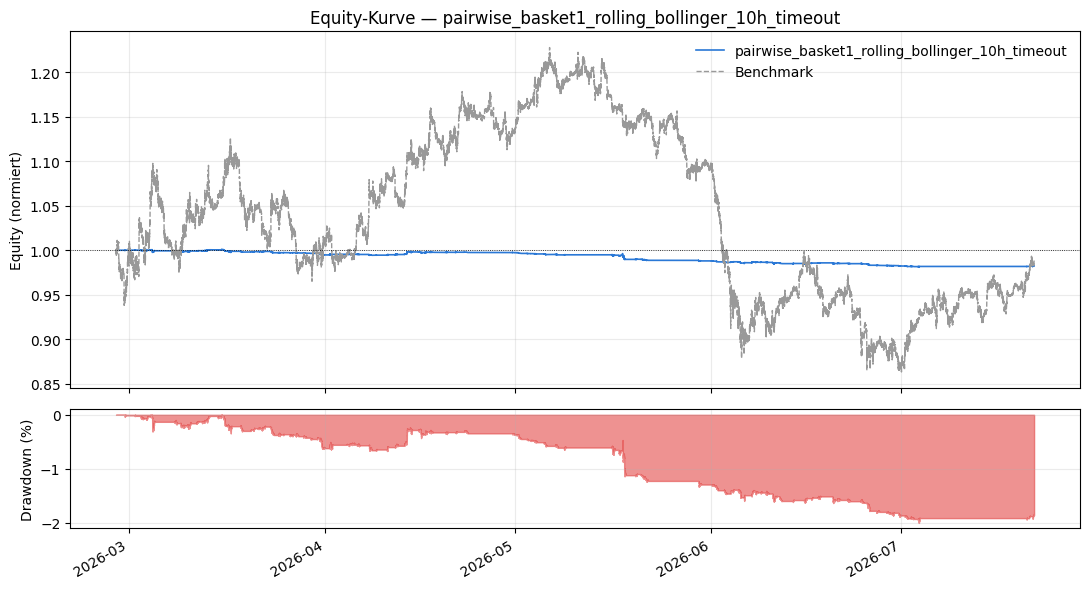

(<Figure size 1100x600 with 2 Axes>,
 (<Axes: title={'center': 'Equity-Kurve — pairwise_basket1_rolling_bollinger_10h_timeout'}, ylabel='Equity (normiert)'>,
  <Axes: ylabel='Drawdown (%)'>))

In [9]:
bt_plots.plot_equity_and_drawdown(result, benchmark_close=benchmark_close)

## 7. Trade-Analyse

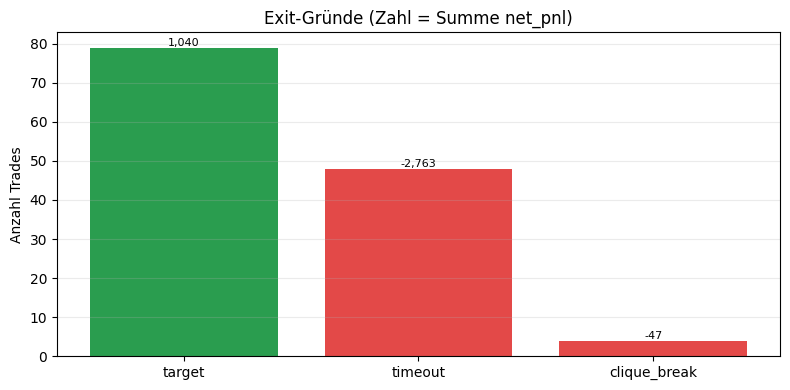

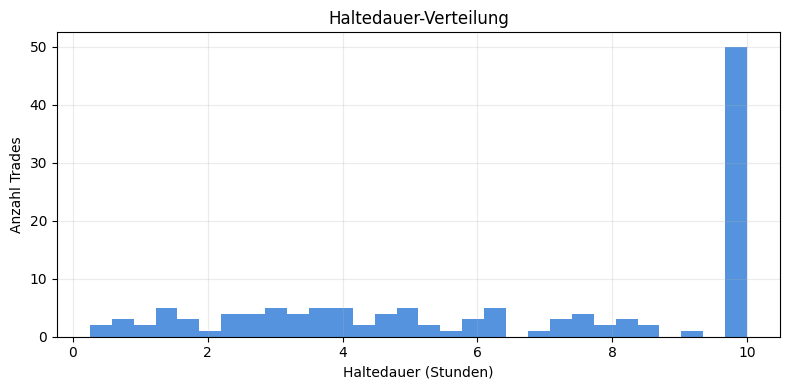

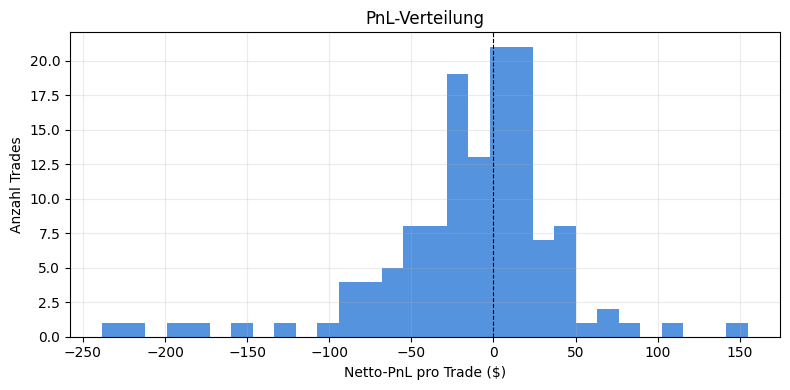

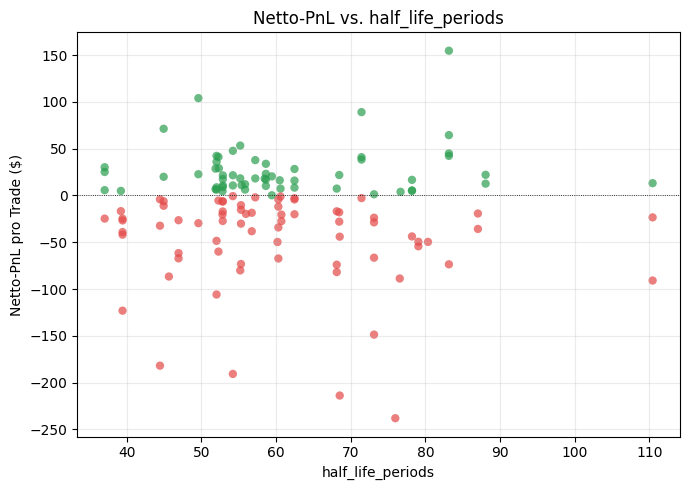

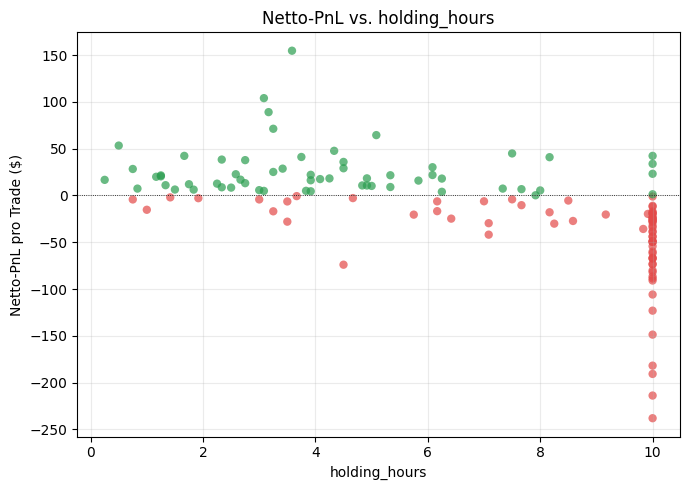

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'Netto-PnL vs. holding_hours'}, xlabel='holding_hours', ylabel='Netto-PnL pro Trade ($)'>)

In [10]:
bt_plots.plot_exit_reason_breakdown(result.trades)
bt_plots.plot_holding_period_histogram(result.trades)
bt_plots.plot_pnl_distribution(result.trades)
bt_plots.plot_pnl_vs_diagnostic(result.trades, "half_life_periods")
bt_plots.plot_pnl_vs_diagnostic(result.trades, "holding_hours")


### Topologischer Struktur-Break: Zensiert-Diagnose

Nur relevant, wenn `TOPO_BREAK_ENABLED=True`. `epsilon_cap` (1.0 raw / 1.3 residual) ist bewusst nicht neu kalibriert -- laut `05_topological_break.ipynb` sind ca. 58.6% aller Cliquen "zensiert" (`death == epsilon_cap`, kein beobachteter Verschmelzungspunkt, siehe dortige Analyse). Zeigt, wie viele der `topological_break`-Exits hier eine zensierte `entry_death` hatten, statt das im Hintergrund zu verstecken.

In [11]:
if TOPO_BREAK_ENABLED:
    epsilon_cap_lookup = 1.0 if CLIQUE_VARIANT.startswith("raw") else 1.3
    topo_trades = result.trades.loc[result.trades["exit_reason"] == "topological_break"]
    n_topo = len(topo_trades)
    n_total = len(result.trades)
    print(f"topological_break: {n_topo} von {n_total} Trades ({100 * n_topo / n_total:.1f}%)" if n_total else "keine Trades")
    if n_topo:
        n_censored = int((topo_trades["entry_death"] >= epsilon_cap_lookup - 1e-9).sum())
        print(f"  davon mit zensiertem entry_death (== epsilon_cap={epsilon_cap_lookup}): {n_censored}/{n_topo} ({100 * n_censored / n_topo:.1f}%)")

    print("\nAufschluesselung nach Basket:")
    for b in BASKETS:
        b_total = int((result.trades["basket"] == b).sum())
        b_topo = int(((result.trades["basket"] == b) & (result.trades["exit_reason"] == "topological_break")).sum())
        print(f"  {b}: {b_topo} von {b_total} Trades ({100 * b_topo / b_total:.1f}%)" if b_total else f"  {b}: keine Trades")
else:
    print("TOPO_BREAK_ENABLED=False -- keine Diagnose (Regel war in diesem Run inaktiv).")


TOPO_BREAK_ENABLED=False -- keine Diagnose (Regel war in diesem Run inaktiv).


## 8. Run speichern

In [12]:
run_dir = bt_runs.save_run(result)
print(f"Gespeichert: {result.run_id}")
print(run_dir)

Gespeichert: 20260811-192738_pairwise-basket1-rolling-bollinger-10h-timeout_1aaef36d
/Users/ryanmikus/Development/Python/00_Quant/26FS_BA/data/processed/backtests/20260811-192738_pairwise-basket1-rolling-bollinger-10h-timeout_1aaef36d


## 9. Vergleich mit früheren Runs

In [13]:
display(bt_runs.list_runs(refresh_index=True).tail(10))

,run_id,created_at,label,description,strategy_name,clique_variant,baskets,backtest_start,backtest_end,fingerprint,n_trades,sharpe_daily,cagr_daily,max_drawdown_pct,runtime_seconds
6,20260811-160539_pairwise-basket1-topo-break-on...,2026-08-11T16:05:39.281932+00:00,pairwise_basket1_topo_break_on,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,8cf8b893,76,-4.297511,-0.066698,-0.030673,19.793534
7,20260811-160444_pairwise-basket1-topo-break-of...,2026-08-11T16:04:44.391237+00:00,pairwise_basket1_topo_break_off,TopologicalBreakRule-Vergleich (an/aus): Pairw...,pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3782a41a,76,-4.297511,-0.066698,-0.030673,9.136886
8,20260811-005244_pairwise-basket1-residual-24h_...,2026-08-11T00:52:44.080658+00:00,pairwise_basket1_residual_24h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5b80acd7,5,-1.321198,-0.003622,-0.003639,2.249917
9,20260811-005231_pairwise-basket1-residual-12h_...,2026-08-11T00:52:31.073432+00:00,pairwise_basket1_residual_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,5eb79671,12,-2.705278,-0.015151,-0.007469,1.218577
10,20260811-005219_pairwise-basket1-residual-6h_3...,2026-08-11T00:52:19.094698+00:00,pairwise_basket1_residual_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,residual_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,3a38b525,6,-2.359453,-0.007265,-0.004354,2.005559
11,20260811-005206_pairwise-basket1-raw-12h_73ae444b,2026-08-11T00:52:06.223666+00:00,pairwise_basket1_raw_12h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_12h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,73ae444b,130,-4.562500,-0.075088,-0.036685,9.066313
12,20260811-005146_pairwise-basket1-raw-6h_6d7ff157,2026-08-11T00:51:46.243373+00:00,pairwise_basket1_raw_6h,Kadenz-/Variantenvergleich: PairwiseZScoreStra...,pairwise_zscore,raw_6h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,6d7ff157,115,-4.774419,-0.076830,-0.036143,9.118448
13,20260811-004926_pairwise-basket1-baseline_f58a...,2026-08-11T00:49:26.367598+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw_24h,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,f58a3bd8,76,-4.297511,-0.066698,-0.030673,10.668369
14,20260808-174720_pairwise-basket1-baseline_7165...,2026-08-08T17:47:20.813223+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,71656dbb,76,-4.297511,-0.066698,-0.030673,12.027416
15,20260807-064911_pairwise-basket1-baseline_7165...,2026-08-07T06:49:11.939619+00:00,pairwise_basket1_baseline,"Baseline: PairwiseZScoreStrategy, nur Basket 1...",pairwise_zscore,raw,[Basket 1],2026-02-27T00:00:00+00:00,2026-07-22T00:00:00+00:00,71656dbb,80,-4.697229,-0.073206,-0.033364,9.682648


In [14]:
# Konkrete Runs zum Vergleich eintragen, z.B.:
# bt_runs.compare_runs([result.run_id, "<anderer-run-id>"])

## 10. Interpretation & nächste Schritte

### Was in dieser Session gefunden/behoben wurde

1. **Ausgangsbefund:** alle Backtests verloren systematisch Geld. Trade-Log-Analyse zeigte: `target`-Exits (echte Mean-Reversion) waren klar profitabel (82% Win-Rate) -- die Richtung/Vorzeichen-Logik war also korrekt. Der Verlust kam von einer **46%-Stop-Rate**: `entry_z` war nur eine Untergrenze, `priority=abs(z)` bevorzugte bei knapper Kapazität die extremsten Kandidaten, und `mu`/`sigma` wurden bei Formation bis zu 7 Tage eingefroren (`_DEFAULT_MAX_STATE_AGE`) -- Positionen eröffneten dadurch teils direkt neben ihrem eigenen `stop_z`.
2. **Fix: rollierende Bollinger-Bänder** (`SpreadDefinition.rolling_zscore`, `BasketParams.bollinger_window_candles`, siehe `src/backtest/types.py`/`strategy.py`/`exit_rules.py`) statt eingefrorenem `mu`/`sigma`. Ergebnis: **Stop-Rate von 46% auf 0%**, Max-Drawdown fast halbiert (-3.07% -> -1.86%), Verlust reduziert (-2.70% -> -1.60%), aber noch nicht profitabel.
3. **10h-Timeout getestet** (`max_holding_candles=120`): leicht schlechter (-1.77%) -- 37% aller Trades schaffen die Reversion nicht in 10h und werden mit Ø -57.57 zwangsgeschlossen, das frisst den Gewinn der schnelleren Trades wieder auf. Mean-Reversion braucht hier meist länger.
4. **Kostenanteil am Bruttogewinn: ~93.5%** (`cost_pct_of_gross_profit`, letzter 10h-Timeout-Run) -- der mit Abstand grösste verbleibende Hebel. Bei 127-131 Trades mit im Schnitt kleinen Ausschlägen (rollierendes Band reagiert schnell) frisst `fee_bps=10` + `slippage_bps=2` pro Trade einen Grossteil des Bruttogewinns auf.
5. **Beta vs. BTC ≈ 0.0008** -- die dollar-neutrale Pairwise-Konstruktion ist tatsächlich marktneutral, kein verstecktes Beta-Exposure.

### Nächste Schritte (nach Ernest Chan, *Algorithmic Trading*, Kap. 3 "Bollinger Bands")

Chan beschreibt exakt dieses Entry/Exit-Schema (`entryZscore`/`exitZscore`), betont aber zwei Punkte, die wir noch NICHT umgesetzt haben:

- [ ] **Lookback = Half-Life statt fixem globalem Fenster.** Chan: *"the length [...] can be a free parameter to be optimized, or it can be set equal to the half-life of mean reversion."* Wir berechnen `half_life_periods` pro Paar bereits (`definition.diagnostics`, aktuell nur als Filter genutzt) -- naheliegend, `bollinger_window_candles` PRO PAAR darauf zu setzen statt global auf 288.
- [ ] **`entry_z`/`exit_z` auf dem Kalibrierungszeitraum optimieren**, statt handgesetzter Werte. Der Calibration/Backtest-Split (Guard G6, Abschnitt 3) existiert bereits, wurde bisher aber nie für eine echte Grid-Search genutzt.
- [ ] **Chans eigene Beispielwerte direkt gegentesten:** `entry_z=1.0, exit_z=0.0` (deutlich enger als unsere `3.0`/`0.5`) -- in seinem GLD-USO-Beispiel damit Sharpe 0.96.
- [ ] **Timeout zwischen 10h und ~3 Tagen** (aktueller Default `max_holding_candles=864`) systematisch abtasten, z.B. 24h/48h.
- [ ] **Transaktionskosten-Sensitivität** (ursprünglich hier als Platzhalter vorgesehen: *"Robustheit bei doppelten Kosten"*) -- bei ~93.5% Kostenanteil am Bruttogewinn zeigt das direkt, wie viel vom Ergebnis reines Kosten-Rauschen ist.
- [ ] Sobald ein profitabler Parametersatz für Basket 1 gefunden ist: auf Basket 2-4 ausweiten (dort bisher nur mit unangepassten Baseline-Parametern getestet, siehe `04_run_comparison.ipynb`) und `TopologicalBreakRule` erneut gegenlaufen lassen (bisher 0 Trades in Basket 1 betroffen, aber 7/217 in Basket 2 bei den alten, viel selteneren `target`-Exits -- mit den neuen, häufigeren Exits könnte sich das Bild ändern).
- [ ] `epsilon_cap` (Discovery-Pipeline, aktuell 1.0/1.3, bewusst unverändert gelassen) erst NACH einer sauberen Strategie-Kalibrierung nochmal anfassen, um Kalibrierungsaufwand nicht doppelt zu leisten.
